In [2]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import os 
import sys
import string
import glob
import rpy2.robjects as robjects
import csv
import math

# Locate the path to where the input files are stored
input_directory = "/mnt/CORDEX_CMIP6_tmp/user_tmp/jbediajimenez/fwi_val_results/monthly_bias/monthly_data"
output_figure_path = "../figures/"

# Read in the PRUDENCE regions

with open("../docs/prudence_regions.csv") as f:
    prudence_region_coords = {
        row["abbreviation"]: {
            "lon": slice(float(row["lon_min"]), float(row["lon_max"])),
            "lat": slice(float(row["lat_min"]), float(row["lat_max"])),
        }
        for row in csv.DictReader(f)
    }


In [3]:
# Define the FWI calculation as a function of ISI and BUI here - we need it for the contours
# Adopted from Quilcaille et al., 2023

def FWI(ISI, BUI):
    """
    Calculates today's Fire Weather Index

    Parameters
    ----------
    ISI: array
        ISI on this day (1)
    BUI: array
        BUI on this day (1)

    Returns
    ----------
    FWI: array
        FWI on this day (1)
    """

    # Preparing fD
    fD = np.nan * np.ones(BUI.shape)

    # Case BUI <= 80
    ind_buiL80 = np.where(BUI <= 80)
    fD[ind_buiL80] = 0.626 * pow(BUI[ind_buiL80], 0.809) + 2.0
    ind_buiG80 = np.where(BUI > 80)
    fD[ind_buiG80] = 1000.0 / (25.0 + 108.64 * np.exp(-0.023 * BUI[ind_buiG80]))
    
    B = 0.1 * ISI * fD

    # Preparing S (just complying to notations of the original script)
    S = np.copy(B)

    # Case of B > 1
    ind_BG1 = np.where(B > 1)
    S[ind_BG1] = np.exp(2.72 * pow(0.434 * np.log(B[ind_BG1]), 0.647))

    # Simply making sure that they are no negative values
    S[np.where(S < 0)] = 0
    return S



In [4]:
# Variables we are interested in

variables = ['bui', 'isi']

# Initialize dictionaries to store the data and regional averages

data_all = {var: {} for var in variables}

# Read all the .Rdata files into a dictionary (17 models + ERA5):

for var in variables:

    var_all = []
    files = sorted(glob.glob(f"{input_directory}/*{var}_monthly.Rdata"))
    
    for f in files:
    
        model_name = os.path.basename(f).replace(f"_{var}_monthly.Rdata", "")

        # Load the RData file into R's environment and pull the object out by its loaded name (monthly_fwi)
        obj = robjects.r[list(robjects.r['load'](f))[0]]

        # Extract the dimensions
        data = np.array(obj.rx2('Data')) # shape (time, lat, lon)
        lons = np.array(obj.rx2('xyCoords').rx2('x'))
        lats = np.array(obj.rx2('xyCoords').rx2('y'))
        dates_start = pd.to_datetime(list(obj.rx2('Dates').rx2('start')))

        # Wrap as xarray (lat forced ascending so the PRUDENCE slices work)
        da = xr.DataArray(
            data,
            dims=["time", "lat", "lon"],
            coords={"time": dates_start, "lat": lats, "lon": lons},
            name=var
        ).sortby("lat")

        # Select JJA (Jun/Jul/Aug), 1980-2020, and average over time -> one 2D (lat, lon) field per model
        # Then, write down the model name in a new dimension
        t = da.time
        data_all[var][model_name] = da.sel(
            time = (t.dt.year >= 1980) & (t.dt.year <= 2020) & (t.dt.month.isin([6, 7, 8]))
        ).mean("time", skipna = True)
        
        print(model_name)

AUTH_WRF451Q
CLMcom-CMCC_CCLM6-0-1-URB
CLMcom-Hereon_CCLM6-0-1
CLMcom-Hereon_GCOAST-AHOIB1-1
CLMcom-Hereon_ICON-CLM-202407-1-1
CLMcom-KUL_CCLM6-0-1-URB-ESG
CNRM-MF_ALADIN64E1
DWD-BSH_ROAM-NBS
ERA5-Land
GERICS_REMO2020-2-2-TEB
GERICS_REMO2020-2-2-iMOVE-LUC
GERICS_REMO2020-2-2-iMOVE
GERICS_REMO2020-2-2
HCLIMcom-SMHI_HCLIM43-ALADIN
ICTP_RegCM5-0
IDL-FCUL_WRF451Q
KNMI_RACMO23E
RMIB-UGent_ALARO1-SFX
AUTH_WRF451Q
CLMcom-CMCC_CCLM6-0-1-URB
CLMcom-Hereon_CCLM6-0-1
CLMcom-Hereon_GCOAST-AHOIB1-1
CLMcom-Hereon_ICON-CLM-202407-1-1
CLMcom-KUL_CCLM6-0-1-URB-ESG
CNRM-MF_ALADIN64E1
DWD-BSH_ROAM-NBS
ERA5-Land
GERICS_REMO2020-2-2-TEB
GERICS_REMO2020-2-2-iMOVE-LUC
GERICS_REMO2020-2-2-iMOVE
GERICS_REMO2020-2-2
HCLIMcom-SMHI_HCLIM43-ALADIN
ICTP_RegCM5-0
IDL-FCUL_WRF451Q
KNMI_RACMO23E
RMIB-UGent_ALARO1-SFX


In [5]:
# Calculate area-weighted spatial averages over each region

model_names = list(data_all["bui"].keys())
regional_averages = {var: {region: [] for region in prudence_region_coords.keys()} for var in variables}
era5_land_regional_averages = {var: {region: [] for region in prudence_region_coords.keys()} for var in variables}

for var in variables:
    
    for model in model_names:
        
        weights = np.cos(np.deg2rad(data_all[var][model].lat))
        weights.name = "weights"
        
        for region, coords in prudence_region_coords.items():
            
            # Select the region
            regional_data = data_all[var][model].sel(lon=coords['lon'], lat=coords['lat'])
            regional_data = regional_data.where(regional_data < 1000) # Put this condition to filter out noise values
            
            # Give the weights for the weighted average
            regional_data_weighted = regional_data.weighted(weights)
            
            # Compute the spatial average over the selected region
            if model == "ERA5-Land":
                era5_land_regional_averages[var][region].append(regional_data_weighted.mean(dim=['lat', 'lon']).values)
            else:
                regional_averages[var][region].append(regional_data_weighted.mean(dim=['lat', 'lon']).values)

# Flatten the data for plotting
flattened_regional_data = {region: {'BUI': {}, 'ISI': {}} for region in prudence_region_coords}
era5_land_regional_data = {region: {'BUI': {}, 'ISI': {}} for region in prudence_region_coords}

for region in prudence_region_coords.keys():
    flattened_regional_data[region]['BUI'] = regional_averages['bui'][region]
    flattened_regional_data[region]['ISI'] = regional_averages['isi'][region]
    era5_land_regional_data[region]['BUI'] = era5_land_regional_averages['bui'][region]
    era5_land_regional_data[region]['ISI'] = era5_land_regional_averages['isi'][region]

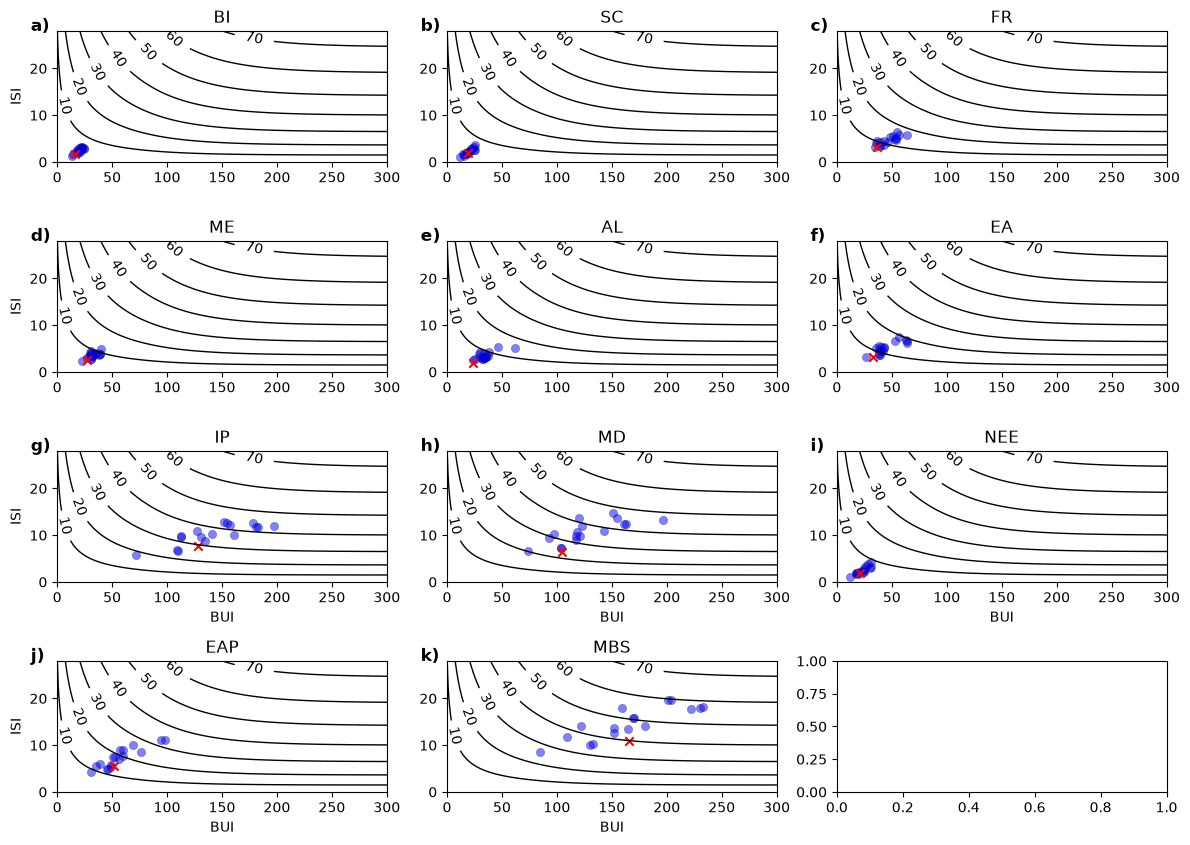

In [6]:
# Plot the distribution of BUI and ISI with FWI contours

# Calculate FWI for contour plotting (same for all regions)
x = np.linspace(0, 500, 500)
y = np.linspace(0, 50, 500)
X, Y = np.meshgrid(x, y)
Z = FWI(Y, X)

# Plotting part
fig, axes = plt.subplots(4, 3, figsize=(12, 9))
axes = axes.flatten()

for i, (region, ax) in enumerate(zip(prudence_region_coords.keys(), axes)):
    bui_all_combined = []
    isi_all_combined = []
    
    bui_all = flattened_regional_data[region]['BUI']
    isi_all = flattened_regional_data[region]['ISI']

    bui_era5_land = era5_land_regional_data[region]['BUI']
    isi_era5_land = era5_land_regional_data[region]['ISI']
    
    # Scatter plot for ensemble members
    ax.scatter(bui_all, isi_all, 
                alpha=0.5, color = 'blue', edgecolor=['black'], 
                linewidths=0.3)
    
    # Scatter plot for ERA5-Land
    ax.scatter(bui_era5_land, isi_era5_land, 
                marker = 'x', color = 'red', alpha=1, 
                linewidths=1.5, label = 'ERA5')

    # Calculate the axes limits
    bui_max = max(bui_all)
    isi_max = max(isi_all)
    
    # Contour Plot
    contour_levels = np.arange(10, 90, 10)
    contours = ax.contour(X, Y, Z, levels = contour_levels, colors = 'black', linewidths = 1)
    manual_positions = [(7, 12), (20, 16), (35, 19), (55, 22), (80, 23), (100, 25), (180, 27)]
    ax.clabel(contours, inline_spacing = 1, inline = True, fontsize = 10, manual = manual_positions)
    
    # Set titles and limits for each subplot
    ax.set_title(region)
    ax.set_xlim(0, 300)
    ax.set_ylim(0, 28)
    
    if i % 3 == 0:
        ax.set_ylabel('ISI')
    if i >= 6:
        ax.set_xlabel('BUI')

    # Add subplot label (a, b, c, d)
    ax.text(-0.08, 1.1, f"{string.ascii_lowercase[i]})", transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='left')

# Adjust the layout and add a single legend
handles, labels = axes[0].get_legend_handles_labels()
plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(output_figure_path + "isi_bui_distribution_prudence_regions.png", dpi = 600)